# Chapter 6 — Statistical Machine Learning
**Sumber:** *Practical Statistics for Data Scientists*, 2nd Ed. (Bruce, Bruce & Gedeck, O'Reilly)

Notebook ini mereproduksi kode Python dari Chapter 6 dan menjelaskan teori di baliknya.

**Tujuan chapter:** Chapter ini membahas metode *statistical machine learning* yang bersifat **data-driven** dan **tidak mengasumsikan struktur model tertentu** (berbeda dengan regresi linear/logistik yang mengasumsikan bentuk linear). Metode yang dibahas:
- **K-Nearest Neighbors (KNN)**: klasifikasi/prediksi berdasarkan kemiripan dengan record-record terdekat.
- **Tree models** (decision tree / CART): aturan "jika–maka" hasil *recursive partitioning*.
- **Ensemble**: **bagging** dan **random forest** (menggabungkan banyak pohon yang dilatih pada bootstrap sample), serta **boosting** (XGBoost), yang membangun model secara bertahap dengan fokus pada kesalahan model sebelumnya.

Kunci dari semua metode ini adalah mengendalikan **trade-off bias–variance** agar model tidak *overfit*, melalui pemilihan hyperparameter dengan **cross-validation**.

**Data:** data pinjaman Lending Club (`loan200.csv`, `loan3000.csv`, `loan_data.csv.gz`) dengan outcome `paid off` / `default`, serta `house_sales.csv` (King County) untuk contoh prediksi nilai kontinu.

## Import Library

In [1]:
import math
import os
import random
from pathlib import Path
from collections import defaultdict
from itertools import product

import pandas as pd
import numpy as np

from sklearn import preprocessing
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from dmba import textDecisionTree

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# Mencegah crash pada XGBoost di beberapa instalasi (konflik library OpenMP)
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

# Seed agar hasil dapat direproduksi
random.seed(1)
np.random.seed(1)

In [2]:
%matplotlib inline

In [3]:
# Lokasi folder data (folder `data/` berada satu level di atas folder `notebooks/`)
DATA = Path('../data')
if not DATA.exists():          # cadangan jika notebook dijalankan dari root repo
    DATA = Path('data')
print('Folder data ditemukan:', DATA.resolve().exists())

Folder data ditemukan: True


## Definisi Path Dataset

In [4]:
LOAN200_CSV = DATA / 'loan200.csv'
LOAN3000_CSV = DATA / 'loan3000.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'
HOUSE_CSV = DATA / 'house_sales.csv'

## 6.1 K-Nearest Neighbors
### A Small Example: Predicting Loan Default
**Teori:** K-Nearest Neighbors (KNN) adalah metode yang sangat sederhana dan tidak membangun "model" eksplisit (*lazy learner*). Untuk setiap record baru yang akan diklasifikasi:
1. Cari $K$ record di data training yang **fiturnya paling mirip** (jaraknya paling dekat).
2. **Klasifikasi:** ambil kelas mayoritas di antara $K$ tetangga tersebut (*majority vote*). Proporsi tiap kelas di antara tetangga juga bisa dipakai sebagai **probabilitas**:
$$\hat{P}(Y = c \mid x) = \frac{1}{K}\sum_{i \in N_K(x)} I(y_i = c)$$
3. **Prediksi numerik (KNN regression):** ambil rata-rata (atau median) nilai outcome dari $K$ tetangga.

Hasil KNN bergantung pada tiga hal: **(a)** bagaimana jarak diukur, **(b)** bagaimana prediktor diskalakan, dan **(c)** berapa nilai $K$.

**Data:** `loan200.csv` berisi 200 pinjaman (plus 1 record target di baris pertama) dengan dua prediktor: `payment_inc_ratio` (rasio cicilan terhadap pendapatan) dan `dti` (*debt-to-income ratio*). Baris 0 adalah pinjaman baru yang ingin diprediksi; KNN dengan $K=20$ dilatih pada sisanya.

In [5]:
loan200 = pd.read_csv(LOAN200_CSV)

predictors = ['payment_inc_ratio', 'dti']
outcome = 'outcome'

newloan = loan200.loc[0:0, predictors]   # record baru (target)
X = loan200.loc[1:, predictors]
y = loan200.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)
print('Record baru:\n', newloan)
print('Kelas:', knn.classes_)
print('Prediksi:', knn.predict(newloan))
print('Probabilitas:', knn.predict_proba(newloan))

Record baru:
    payment_inc_ratio   dti
0                9.0  22.5
Kelas: ['default' 'paid off']
Prediksi: ['paid off']
Probabilitas: [[0.45 0.55]]


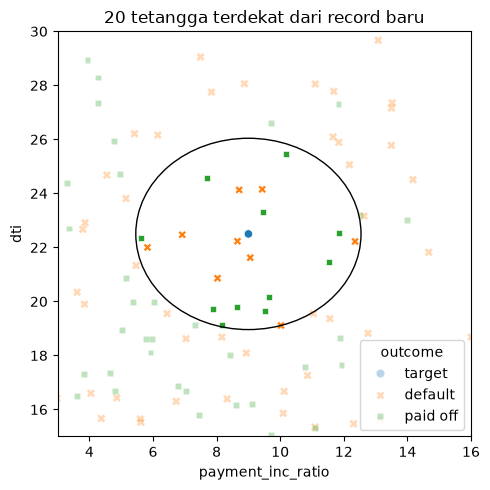

Jarak tetangga terjauh (radius lingkaran): 3.541
outcome
paid off    11
default      9
Name: count, dtype: int64


In [6]:
# Visualisasi 20 tetangga terdekat dari record baru
nbrs = knn.kneighbors(newloan)
maxDistance = np.max(nbrs[0][0])

fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(x='payment_inc_ratio', y='dti', style='outcome',
                hue='outcome', data=loan200, alpha=0.3, ax=ax)
sns.scatterplot(x='payment_inc_ratio', y='dti', style='outcome',
                hue='outcome',
                data=pd.concat([loan200.loc[0:0, :], loan200.loc[nbrs[1][0] + 1, :]]),
                ax=ax, legend=False)
ellipse = Ellipse(xy=newloan.values[0],
                  width=2 * maxDistance, height=2 * maxDistance,
                  edgecolor='black', fc='None', lw=1)
ax.add_patch(ellipse)
ax.set_xlim(3, 16)
ax.set_ylim(15, 30)
ax.set_title('20 tetangga terdekat dari record baru')

plt.tight_layout()
plt.show()
print('Jarak tetangga terjauh (radius lingkaran):', round(maxDistance, 3))
print(loan200.loc[nbrs[1][0] + 1, 'outcome'].value_counts())

**Interpretasi:** TODO-knn_small

### Distance Metrics
**Teori:** Kemiripan antar record diukur dengan **metrik jarak**. Untuk dua vektor $x = (x_1,\dots,x_p)$ dan $u = (u_1,\dots,u_p)$:
- **Euclidean distance** (paling umum, jarak "garis lurus"):
$$d_E(x,u) = \sqrt{(x_1-u_1)^2 + (x_2-u_2)^2 + \cdots + (x_p-u_p)^2}$$
- **Manhattan distance** (jarak "blok kota", jumlah selisih absolut):
$$d_M(x,u) = |x_1-u_1| + |x_2-u_2| + \cdots + |x_p-u_p|$$
- **Mahalanobis distance** memperhitungkan korelasi antar variabel: $d(x,u)=\sqrt{(x-u)^T S^{-1}(x-u)}$, dengan $S$ matriks kovarians. Kelebihannya: dua variabel yang sangat berkorelasi tidak "dihitung dua kali". Kekurangannya: komputasi lebih mahal.

Euclidean dan Manhattan adalah kasus khusus **Minkowski distance** $\left(\sum |x_j-u_j|^q\right)^{1/q}$ dengan $q=2$ dan $q=1$. Di scikit-learn, metrik diatur lewat parameter `metric` / `p` pada `KNeighborsClassifier`.

Kode berikut (tambahan, bukan dari notebook resmi) menghitung kedua jarak secara manual dan membandingkan tetangga terdekat yang dihasilkan.

In [7]:
x0 = newloan.values[0]
diff = X.values - x0
euclid = np.sqrt((diff ** 2).sum(axis=1))
manhat = np.abs(diff).sum(axis=1)
print('Record baru:', x0)
print('Record 1   :', X.values[0])
print(f'Euclidean distance ke record 1 = {euclid[0]:.3f}')
print(f'Manhattan distance ke record 1 = {manhat[0]:.3f}')

# Bandingkan himpunan 20 tetangga terdekat dengan p=2 (Euclidean) vs p=1 (Manhattan)
knn_man = KNeighborsClassifier(n_neighbors=20, p=1).fit(X, y)
nb_e = set(knn.kneighbors(newloan)[1][0])
nb_m = set(knn_man.kneighbors(newloan)[1][0])
print('Jumlah tetangga yang sama (Euclidean vs Manhattan):', len(nb_e & nb_m), 'dari 20')
print('Probabilitas (Manhattan):', knn_man.predict_proba(newloan))

Record baru: [ 9.  22.5]
Record 1   : [ 5.46933 21.33   ]
Euclidean distance ke record 1 = 3.719
Manhattan distance ke record 1 = 4.701
Jumlah tetangga yang sama (Euclidean vs Manhattan): 19 dari 20
Probabilitas (Manhattan): [[0.4 0.6]]


**Interpretasi:** TODO-distance

### One Hot Encoder
**Teori:** KNN (dan banyak metode ML lain seperti regresi tanpa intercept, neural network) membutuhkan input **numerik**. Variabel kategorikal diubah menjadi **one-hot encoding**: satu kolom biner (0/1) untuk **setiap** level kategori.

Perbedaan dengan regresi (Chapter 4): pada regresi linear dengan intercept kita memakai $P-1$ dummy (*reference coding*) untuk menghindari multikolinearitas sempurna. Pada KNN dan tree, **semua $P$ level** biasanya dipertahankan (`drop_first=False`), karena tidak ada masalah multikolinearitas dan setiap kategori ikut berkontribusi pada jarak.

Contoh di bawah (tambahan) memperlihatkan one-hot encoding variabel `home_` (status kepemilikan rumah) pada `loan_data`.

In [8]:
loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data = loan_data.drop(columns=['Unnamed: 0', 'status'])
loan_data['outcome'] = pd.Categorical(loan_data['outcome'],
                                      categories=['paid off', 'default'],
                                      ordered=True)

print(loan_data['home_'].head(6).to_frame())
print()
# One-hot encoding: satu kolom 0/1 untuk setiap level (drop_first=False)
print(pd.get_dummies(loan_data['home_'], dtype=int).head(6))

  home_
0  RENT
1   OWN
2  RENT
3  RENT
4  RENT
5  RENT

   MORTGAGE  OWN  RENT
0         0    0     1
1         0    1     0
2         0    0     1
3         0    0     1
4         0    0     1
5         0    0     1


**Interpretasi:** TODO-onehot

### Standardization (Normalization, Z-Scores)
**Teori:** Karena jarak dihitung dari selisih nilai, variabel dengan **skala besar mendominasi** perhitungan jarak. Contoh: `revol_bal` (saldo kredit bergulir, dalam dolar, bisa puluhan ribu) akan jauh lebih berpengaruh daripada `dti` (puluhan) atau `payment_inc_ratio`. Solusinya adalah **standardisasi** (z-score):
$$z = \frac{x - \bar{x}}{s}$$
Setelah distandardisasi, semua variabel memiliki rata-rata 0 dan simpangan baku 1, sehingga setiap variabel berkontribusi setara pada jarak. Alternatif lain: *min–max scaling* atau normalisasi berbasis median/MAD (lebih robust terhadap outlier).

**Catatan penting:** parameter scaler (mean, sd) dihitung dari **data training** lalu diterapkan ke data baru, bukan dihitung ulang pada data baru.

Pertama, KNN dengan $K=5$ dijalankan **tanpa** standardisasi pada empat prediktor.

In [9]:
predictors = ['payment_inc_ratio', 'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'

newloan = loan_data.loc[0:0, predictors]
print(newloan)
X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

nbrs = knn.kneighbors(newloan)
print('\n5 tetangga terdekat TANPA standardisasi:')
print(X.iloc[nbrs[1][0], :])

   payment_inc_ratio  dti  revol_bal  revol_util
0             2.3932  1.0       1687         9.4



5 tetangga terdekat TANPA standardisasi:


       payment_inc_ratio   dti  revol_bal  revol_util
35536            1.47212  1.46       1686        10.0
33651            3.38178  6.37       1688         8.4
25863            2.36303  1.39       1691         3.5
42953            1.28160  7.14       1684         3.9
43599            4.12244  8.98       1684         7.2


In [10]:
newloan = loan_data.loc[0:0, predictors]
X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

scaler = preprocessing.StandardScaler()
scaler.fit(X * 1.0)

X_std = scaler.transform(X * 1.0)
newloan_std = scaler.transform(newloan * 1.0)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_std, y)

nbrs = knn.kneighbors(newloan_std)
print('5 tetangga terdekat DENGAN standardisasi:')
print(X.iloc[nbrs[1][0], :])

5 tetangga terdekat DENGAN standardisasi:
       payment_inc_ratio   dti  revol_bal  revol_util
2080             2.61091  1.03       1218         9.7
1438             2.34343  0.51        278         9.9
30215            2.71200  1.34       1075         8.5
28542            2.39760  0.74       2917         7.4
44737            2.34309  1.37        488         7.2


**Interpretasi:** TODO-standardize

### Choosing K
**Teori:** Pemilihan $K$ sangat menentukan performa KNN dan merupakan contoh klasik **bias–variance trade-off**:
- **$K$ kecil** (misal $K=1$): model sangat fleksibel, menangkap pola lokal, tetapi juga **noise** sehingga **overfitting** (variance tinggi).
- **$K$ besar**: prediksi lebih halus (*smoothing*), tetapi bisa kehilangan struktur lokal yang penting sehingga **underfitting** (bias tinggi). Pada ekstremnya $K=N$, semua record diprediksi sebagai kelas mayoritas.

Tidak ada aturan baku; $K$ terbaik biasanya dipilih dengan mengukur akurasi pada **data validasi / cross-validation**. Umumnya $K$ yang baik berada di kisaran 1 sampai 20, dan $K$ ganjil sering dipakai untuk menghindari seri pada klasifikasi biner. Semakin besar noise (sinyal lemah), semakin besar $K$ yang optimal.

Kode tambahan berikut mengevaluasi beberapa nilai $K$ dengan **5-fold cross-validation** pada 4 prediktor yang sudah distandardisasi. Untuk menghemat waktu dipakai sampel acak **10.000 record** (bukan seluruh 45 ribu).

K =    1  ->  akurasi CV = 0.5250


K =    5  ->  akurasi CV = 0.5525


K =   11  ->  akurasi CV = 0.5617


K =   21  ->  akurasi CV = 0.5720


K =   51  ->  akurasi CV = 0.5841


K =  101  ->  akurasi CV = 0.5871


K =  201  ->  akurasi CV = 0.5874


K =  401  ->  akurasi CV = 0.5868


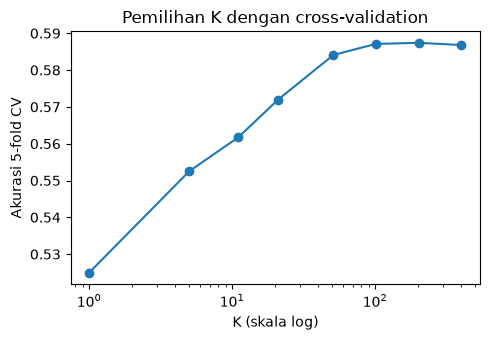

In [11]:
sample = loan_data.sample(10000, random_state=1)
X_k = preprocessing.StandardScaler().fit_transform(sample[predictors] * 1.0)
y_k = sample[outcome]

k_values = [1, 5, 11, 21, 51, 101, 201, 401]
cv_acc = []
for k in k_values:
    acc = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_k, y_k,
                          cv=5, scoring='accuracy').mean()
    cv_acc.append(acc)
    print(f'K = {k:4d}  ->  akurasi CV = {acc:.4f}')

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(k_values, cv_acc, marker='o')
ax.set_xscale('log')
ax.set_xlabel('K (skala log)')
ax.set_ylabel('Akurasi 5-fold CV')
ax.set_title('Pemilihan K dengan cross-validation')
plt.tight_layout()
plt.show()

**Interpretasi:** TODO-choose_k

### KNN as a Feature Engine
**Teori:** Dalam praktik, KNN jarang dipakai sebagai model akhir, tetapi sering dipakai sebagai **feature engine**: hasil prediksi KNN (misalnya probabilitas kelas) ditambahkan sebagai **fitur baru** ke model lain (regresi logistik, tree, boosting). Ide ini mirip dengan *ensemble/stacking*: KNN menangkap **informasi lokal** (kemiripan dengan record lain) yang sulit ditangkap model global.

Di buku, KNN dengan $K=20$ dilatih pada variabel kredit (`dti`, `revol_bal`, `revol_util`, `open_acc`, `delinq_2yrs_zero`, `pub_rec_zero`) untuk menghasilkan **`borrower_score`**, yaitu proporsi tetangga yang *paid off* (skor 0 sampai 1, semakin tinggi semakin "baik" peminjamnya).

**Peringatan:** jika skor dihitung pada data yang sama dengan data training (seperti contoh ini), setiap record ikut menjadi tetangga dirinya sendiri sehingga terjadi *information leakage*. Dalam praktik sebaiknya skor dihitung secara *out-of-fold* (cross-validation).

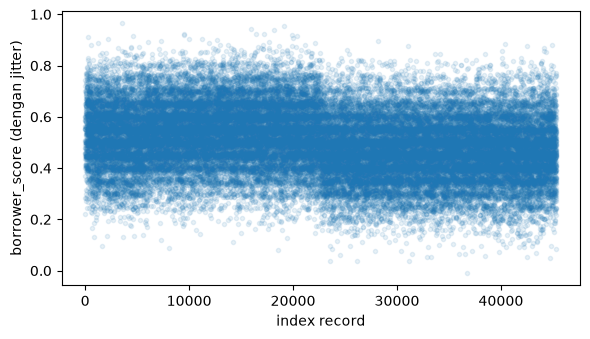

count    45342.000000
mean         0.501091
std          0.128728
min          0.000000
25%          0.400000
50%          0.500000
75%          0.600000
max          0.950000
Name: borrower_score, dtype: float64

outcome
paid off    0.465295
default     0.536886
Name: borrower_score, dtype: float64


In [12]:
predictors = ['dti', 'revol_bal', 'revol_util', 'open_acc',
              'delinq_2yrs_zero', 'pub_rec_zero']
outcome = 'outcome'

X = loan_data[predictors]
y = loan_data[outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)
proba = knn.predict_proba(X)[:, 0]   # kolom 0 = kelas 'paid off'

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(range(len(X)), [bs + random.gauss(0, 0.015) for bs in proba],
           alpha=0.1, marker='.')
ax.set_xlabel('index record')
ax.set_ylabel('borrower_score (dengan jitter)')
plt.tight_layout()
plt.show()

loan_data['borrower_score'] = proba
print(loan_data['borrower_score'].describe())
print()
print(loan_data.groupby('outcome', observed=True)['borrower_score'].mean())

**Interpretasi:** TODO-feature_engine

## 6.2 Tree Models
### A Simple Example
**Teori:** Tree model (dikenal juga sebagai *decision tree*, **CART** = *Classification And Regression Trees*) menghasilkan sekumpulan aturan **"if–then–else"** yang mudah dipahami. Contoh: *"Jika `borrower_score` < 0.575 dan `payment_inc_ratio` ≥ 10.4, prediksi default."*

Istilah penting:
- **Split value:** nilai prediktor yang membagi record menjadi dua kelompok (≤ dan >).
- **Node:** titik keputusan (*decision node*) atau titik akhir.
- **Leaf (daun):** node terminal yang memberi prediksi akhir (kelas mayoritas atau rata-rata).
- **Impurity:** ukuran sejauh mana kelas-kelas bercampur dalam sebuah partisi.
- **Pruning:** memangkas pohon yang terlalu besar untuk mengurangi overfitting.

Kelebihan tree: mudah divisualisasikan dan dijelaskan, mampu menangkap **interaksi** dan **non-linearitas** secara otomatis, dan tidak memerlukan standardisasi. Kekurangan: satu pohon cenderung **tidak stabil** (variance tinggi), sehingga sering digabung menjadi ensemble.

**Data:** `loan3000.csv` (3000 pinjaman) dengan prediktor `borrower_score` (dari KNN di atas) dan `payment_inc_ratio`. Pohon dibangun dengan `criterion='entropy'` dan `min_impurity_decrease=0.003` (split hanya dibuat jika menurunkan impurity minimal 0,003).

**Catatan deviasi:** buku memakai `dmba.plotDecisionTree`, yang membutuhkan program *Graphviz* (tidak tersedia di lingkungan ini). Sebagai gantinya dipakai `sklearn.tree.plot_tree` yang menghasilkan gambar pohon yang sama.

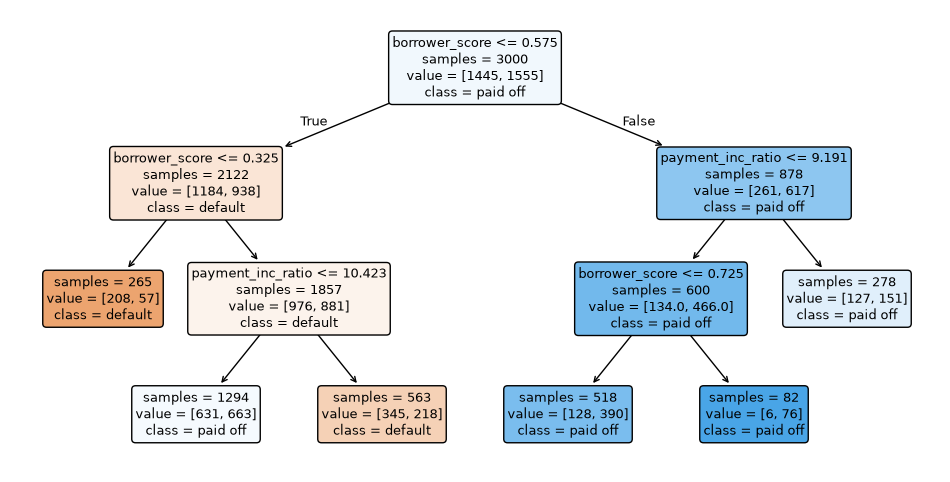

In [13]:
loan3000 = pd.read_csv(LOAN3000_CSV)

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                   min_impurity_decrease=0.003)
loan_tree.fit(X, y)

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(loan_tree, feature_names=predictors, class_names=loan_tree.classes_,
          filled=True, rounded=True, impurity=False, ax=ax, fontsize=9)
plt.show()

In [14]:
# Representasi teks dari pohon (fungsi dari paket dmba)
print(textDecisionTree(loan_tree))

node=0 test node: go to node 1 if 0 <= 0.5750000178813934 else to node 6
  node=1 test node: go to node 2 if 0 <= 0.32500000298023224 else to node 3
    node=2 leaf node: [[np.float64(0.785), np.float64(0.215)]]
    node=3 test node: go to node 4 if 1 <= 10.42264986038208 else to node 5
      node=4 leaf node: [[np.float64(0.488), np.float64(0.512)]]
      node=5 leaf node: [[np.float64(0.613), np.float64(0.387)]]
  node=6 test node: go to node 7 if 1 <= 9.19082498550415 else to node 10
    node=7 test node: go to node 8 if 0 <= 0.7249999940395355 else to node 9
      node=8 leaf node: [[np.float64(0.247), np.float64(0.753)]]
      node=9 leaf node: [[np.float64(0.073), np.float64(0.927)]]
    node=10 leaf node: [[np.float64(0.457), np.float64(0.543)]]


**Interpretasi:** TODO-simple_tree

### The Recursive Partitioning Algorithm
**Teori:** Pohon dibangun dengan **recursive partitioning**, algoritma *greedy* sebagai berikut. Misalkan ada outcome $Y$ dan prediktor $X_1,\dots,X_p$, serta partisi $A$ (awalnya seluruh data):
1. Untuk setiap prediktor $X_j$:
   - untuk setiap kemungkinan nilai split $s_j$ dari $X_j$: bagi $A$ menjadi $A_1$ (record dengan $X_j < s_j$) dan $A_2$ (record dengan $X_j \ge s_j$), lalu hitung homogenitas kelas di $A_1$ dan $A_2$;
   - pilih $s_j$ yang menghasilkan homogenitas terbaik.
2. Pilih pasangan $(X_j, s_j)$ terbaik secara keseluruhan.
3. Terapkan split tersebut, lalu **ulangi secara rekursif** pada $A_1$ dan $A_2$.
4. Berhenti jika partisi sudah cukup homogen atau tidak ada perbaikan yang berarti.

Hasilnya adalah partisi ruang prediktor menjadi **persegi panjang** (*rectangles*) yang sejajar sumbu, masing-masing dengan prediksi kelas mayoritasnya. Plot berikut (dari buku) menggambarkan partisi yang dihasilkan pohon di atas.

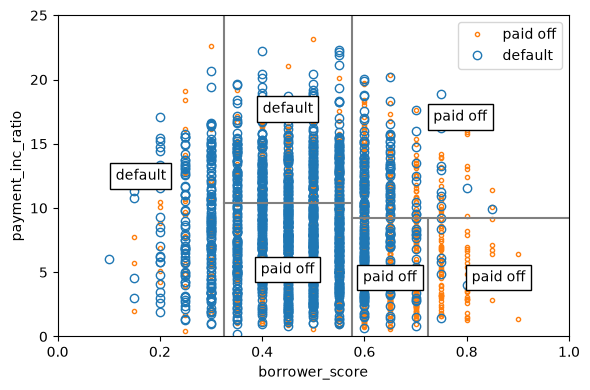

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))

loan3000.loc[loan3000.outcome=='paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
loan3000.loc[loan3000.outcome=='default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')

# Garis-garis split (nilai diambil dari pohon di atas)
x0 = 0.575
x1a = 0.325; y1b = 9.191
y2a = 10.423; x2b = 0.725
ax.plot((x0, x0), (0, 25), color='grey')
ax.plot((x1a, x1a), (0, 25), color='grey')
ax.plot((x0, 1), (y1b, y1b), color='grey')
ax.plot((x1a, x0), (y2a, y2a), color='grey')
ax.plot((x2b, x2b), (0, y1b), color='grey')

labels = [('default', (x1a / 2, 25 / 2)),
          ('default', ((x0 + x1a) / 2, (25 + y2a) / 2)),
          ('paid off', ((x0 + x1a) / 2, y2a / 2)),
          ('paid off', ((1 + x0) / 2, (y1b + 25) / 2)),
          ('paid off', ((1 + x2b) / 2, (y1b + 0) / 2)),
          ('paid off', ((x0 + x2b) / 2, (y1b + 0) / 2)),
         ]
for label, (x, y) in labels:
    ax.text(x, y, label, bbox={'facecolor': 'white'},
            verticalalignment='center', horizontalalignment='center')

plt.tight_layout()
plt.show()

**Interpretasi:** TODO-recursive

### Measuring Homogeneity or Impurity
**Teori:** Untuk memilih split terbaik, dibutuhkan ukuran **impurity** (ketidakmurnian) $I(A)$ sebuah partisi. Misalkan $p$ adalah proporsi record kelas tertentu (misal *default*) dalam partisi $A$ (untuk kasus dua kelas):
- **Accuracy / misclassification error:** $I(A) = \min(p, 1-p)$. Jarang dipakai karena kurang sensitif.
- **Gini impurity:** $I(A) = p(1-p)$; untuk banyak kelas $I(A) = \sum_k p_k(1-p_k) = 1-\sum_k p_k^2$. Ini adalah default pada scikit-learn.
- **Entropy (information):** $I(A) = -p\log_2(p) - (1-p)\log_2(1-p)$; untuk banyak kelas $-\sum_k p_k\log_2 p_k$.

Semua ukuran bernilai **0** saat partisi murni ($p=0$ atau $p=1$) dan **maksimum** saat $p=0{,}5$. Kualitas sebuah split diukur dari **penurunan impurity tertimbang**:
$$\Delta I = I(A) - \left[\frac{|A_1|}{|A|} I(A_1) + \frac{|A_2|}{|A|} I(A_2)\right]$$
Split dengan $\Delta I$ terbesar (*information gain* untuk entropy) yang dipilih. Gini dan entropy lebih disukai daripada akurasi karena merupakan fungsi **cekung (concave)**, sehingga split yang membuat salah satu anak lebih murni tetap dihargai walaupun jumlah salah klasifikasi tidak berubah.

In [16]:
def entropyFunction(x):
    if x == 0: return 0
    return -x * math.log(x, 2) - (1 - x) * math.log(1 - x, 2)

def giniFunction(x):
    return x * (1 - x)

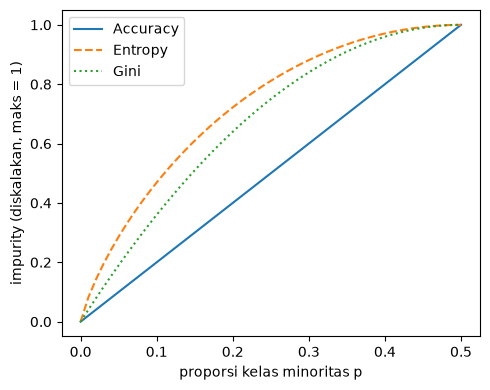

p = 0.10: accuracy = 0.200, gini(skala) = 0.360, entropy = 0.469
p = 0.25: accuracy = 0.500, gini(skala) = 0.750, entropy = 0.811
p = 0.50: accuracy = 1.000, gini(skala) = 1.000, entropy = 1.000


In [17]:
x = np.linspace(0, 0.5, 50)
impure = pd.DataFrame({
    'x': x,
    'Accuracy': 2 * x,
    'Gini': [giniFunction(xi) / giniFunction(.5) for xi in x],
    'Entropy': [entropyFunction(xi) for xi in x],
})

fig, ax = plt.subplots(figsize=(5, 4))

impure.plot(x='x', y='Accuracy', ax=ax, linestyle='solid')
impure.plot(x='x', y='Entropy', ax=ax, linestyle='--')
impure.plot(x='x', y='Gini', ax=ax, linestyle=':')
ax.set_xlabel('proporsi kelas minoritas p')
ax.set_ylabel('impurity (diskalakan, maks = 1)')

plt.tight_layout()
plt.show()

for p in [0.1, 0.25, 0.5]:
    print(f'p = {p:.2f}: accuracy = {2*p:.3f}, gini(skala) = {giniFunction(p)/giniFunction(.5):.3f}, '
          f'entropy = {entropyFunction(p):.3f}')

**Interpretasi:** TODO-impurity

### Stopping the Tree from Growing
**Teori:** Jika dibiarkan, pohon akan terus membagi data sampai setiap daun murni, sehingga mempelajari **noise** dan **overfit**. Ada dua pendekatan pengendalian:
1. **Stopping rules (pre-pruning):** hentikan split jika partisi terlalu kecil, atau split tidak memberi penurunan impurity yang berarti. Di scikit-learn: `min_samples_split`, `min_samples_leaf`, `max_depth`, `min_impurity_decrease`. Di R (`rpart`): `minsplit`, `minbucket`, dan **complexity parameter** `cp`.
2. **Pruning (post-pruning):** tumbuhkan pohon besar lalu pangkas cabang yang tidak memperbaiki akurasi pada data validasi. Di scikit-learn tersedia *cost-complexity pruning* (`ccp_alpha`), dengan biaya $C_\alpha(T) = \text{Err}(T) + \alpha\,|T|$, di mana $|T|$ adalah jumlah daun.

Nilai hyperparameter optimal dipilih dengan **cross-validation**. Kode tambahan berikut membandingkan akurasi training vs 5-fold CV untuk beberapa nilai `max_depth` pada data `loan3000`.

  max_depth  n_leaves  train_acc  cv_acc
0         1         2     0.6003  0.6003
1         2         4     0.6003  0.6003
2         3         8     0.6123  0.6057
3         4        16     0.6243  0.6023
4         5        30     0.6307  0.6093
5         6        48     0.6447  0.6013
6         8        92     0.6577  0.5997
7        10       161     0.6843  0.5883
8        15       421     0.7627  0.5823
9      None      1245     0.9987  0.5690


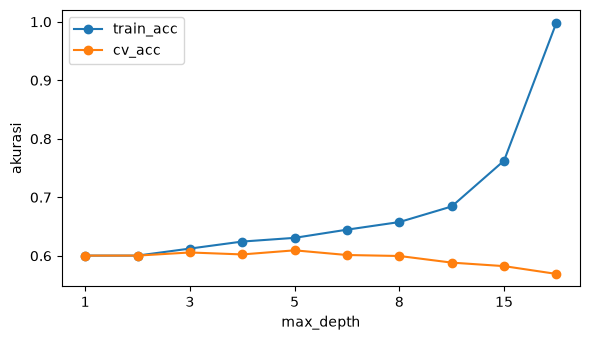

In [18]:
# X dan y didefinisikan ulang karena variabel `y` tertimpa oleh loop label pada plot sebelumnya
X = loan3000[['borrower_score', 'payment_inc_ratio']]
y = loan3000['outcome']
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    tree = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    cv = cross_val_score(tree, X, y, cv=5, scoring='accuracy').mean()
    tree.fit(X, y)
    rows.append({'max_depth': str(depth), 'n_leaves': tree.get_n_leaves(),
                 'train_acc': tree.score(X, y), 'cv_acc': cv})
depth_df = pd.DataFrame(rows)
print(depth_df.round(4))

ax = depth_df.plot(x='max_depth', y=['train_acc', 'cv_acc'], marker='o', figsize=(6, 3.5))
ax.set_ylabel('akurasi')
plt.tight_layout()
plt.show()

**Interpretasi:** TODO-stopping

### Predicting a Continuous Value
**Teori:** Tree juga bisa dipakai untuk outcome **numerik** (*regression tree*). Algoritmanya sama, tetapi:
- **Impurity** diukur dengan **simpangan kuadrat dari rata-rata** di setiap partisi (sum of squared errors), sehingga split dipilih yang paling menurunkan SSE:
$$I(A) = \sum_{i \in A} (y_i - \bar{y}_A)^2$$
- **Prediksi** di setiap daun = **rata-rata** outcome record di daun tersebut.
- Performa dievaluasi dengan **RMSE** (seperti pada regresi).

Hasilnya adalah fungsi **berundak (step function)**, bukan garis halus. Notebook resmi tidak memuat contoh ini; kode tambahan berikut membangun `DecisionTreeRegressor` untuk memprediksi `AdjSalePrice` dari `SqFtTotLiving` pada data `house_sales.csv` (Chapter 4).

max_depth=   2: leaves=    4  RMSE train=284,466  RMSE test=289,069
max_depth=   4: leaves=   16  RMSE train=248,425  RMSE test=277,848
max_depth=   8: leaves=  177  RMSE train=232,593  RMSE test=297,082
max_depth=None: leaves=  834  RMSE train=215,234  RMSE test=314,597


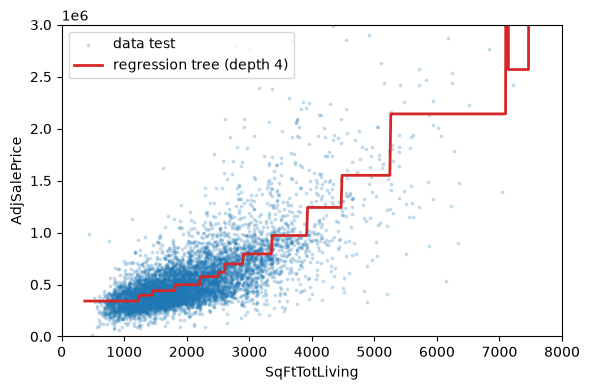

In [19]:
house = pd.read_csv(HOUSE_CSV, sep='\t')
house_X = house[['SqFtTotLiving']]
house_y = house['AdjSalePrice']
tr_X, te_X, tr_y, te_y = train_test_split(house_X, house_y, test_size=0.3, random_state=1)

for depth in [2, 4, 8, None]:
    reg_tree = DecisionTreeRegressor(max_depth=depth, random_state=1).fit(tr_X, tr_y)
    rmse_tr = np.sqrt(metrics.mean_squared_error(tr_y, reg_tree.predict(tr_X)))
    rmse_te = np.sqrt(metrics.mean_squared_error(te_y, reg_tree.predict(te_X)))
    print(f'max_depth={str(depth):>4}: leaves={reg_tree.get_n_leaves():5d}  '
          f'RMSE train={rmse_tr:,.0f}  RMSE test={rmse_te:,.0f}')

reg_tree = DecisionTreeRegressor(max_depth=4, random_state=1).fit(tr_X, tr_y)
grid = pd.DataFrame({'SqFtTotLiving': np.linspace(house_X.min().iloc[0], 8000, 500)})
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(te_X, te_y, s=3, alpha=0.2, label='data test')
ax.plot(grid, reg_tree.predict(grid), color='C3', lw=2, label='regression tree (depth 4)')
ax.set_xlim(0, 8000); ax.set_ylim(0, 3e6)
ax.set_xlabel('SqFtTotLiving'); ax.set_ylabel('AdjSalePrice')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretasi:** TODO-regtree

## 6.3 Bagging and the Random Forest
### Bagging
**Teori:** Prinsip *wisdom of the crowd*: rata-rata dari banyak model sering lebih akurat daripada satu model. **Ensemble** menggabungkan prediksi banyak model. **Bagging** (*bootstrap aggregating*, Breiman 1994):
1. Ambil **bootstrap sample** (sampel *dengan pengembalian*) berukuran $n$ dari data training.
2. Latih model (biasanya pohon tanpa pruning) pada sampel tersebut.
3. Ulangi $M$ kali, menghasilkan $\hat f_1,\dots,\hat f_M$.
4. Prediksi: rata-rata $\hat f(x)=\frac{1}{M}\sum_m \hat f_m(x)$ (regresi) atau **majority vote** (klasifikasi).

Karena setiap pohon sangat fleksibel (bias rendah, variance tinggi), merata-ratakan banyak pohon akan **menurunkan variance** tanpa banyak menaikkan bias.

### Random Forest
**Random forest** menambahkan satu langkah pada bagging: pada **setiap split**, hanya **subset acak** dari prediktor yang dipertimbangkan (default untuk klasifikasi: $\sqrt{p}$ prediktor; scikit-learn: `max_features='sqrt'`). Ini membuat pohon-pohon **kurang berkorelasi** satu sama lain sehingga rata-ratanya lebih efektif menurunkan variance.

**Out-of-bag (OOB) error:** setiap bootstrap sample hanya memuat sekitar $1-(1-1/n)^n \approx 63{,}2\%$ record unik. Sisa ±36,8% (*out-of-bag*) dapat dipakai sebagai data validasi "gratis" untuk pohon tersebut. Agregasi prediksi OOB memberi estimasi error tanpa perlu cross-validation terpisah (`oob_score=True`).

Random forest dengan 500 pohon dilatih pada `loan3000`. `oob_decision_function_` berisi probabilitas OOB untuk tiap record (kolom: `default`, `paid off`).

In [20]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

rf = RandomForestClassifier(n_estimators=500, random_state=1,
                            oob_score=True, n_jobs=-1)
rf.fit(X, y)
print('Kelas:', rf.classes_)
print(rf.oob_decision_function_)
print('OOB accuracy:', round(rf.oob_score_, 4))

Kelas: ['default' 'paid off']
[[0.18131868 0.81868132]
 [0.26704545 0.73295455]
 [0.93333333 0.06666667]
 ...
 [1.         0.        ]
 [0.73157895 0.26842105]
 [0.68085106 0.31914894]]
OOB accuracy: 0.5753


Bagaimana akurasi OOB berubah ketika jumlah pohon bertambah? Buku melatih random forest untuk $n$ = 20, 25, …, 505 pohon (99 model). **Untuk menghemat waktu, di sini langkahnya diperbesar menjadi 25** (20, 45, …, 495), sehingga hanya 20 model yang dilatih; pola kurvanya tetap sama.

In [21]:
n_estimator = list(range(20, 510, 25))   # buku: range(20, 510, 5)
oobScores = []
for n in n_estimator:
    rf = RandomForestClassifier(n_estimators=n,
                                criterion='entropy', max_depth=5,
                                random_state=1, oob_score=True, n_jobs=-1)
    rf.fit(X, y)
    oobScores.append(rf.oob_score_)

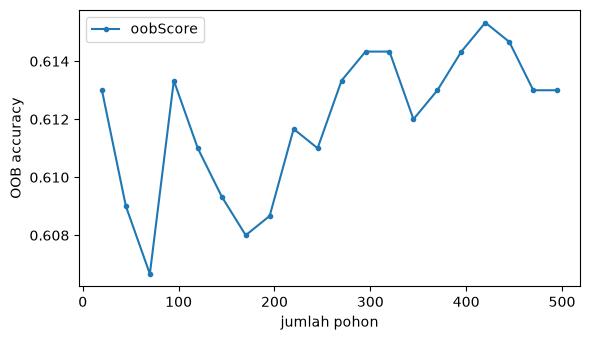

      n  oobScore
0    20  0.613000
1    45  0.609000
2    70  0.606667
5   145  0.609333
10  270  0.613333
19  495  0.613000


In [22]:
oob_df = pd.DataFrame({'n': n_estimator, 'oobScore': oobScores})
ax = oob_df.plot(x='n', y='oobScore', marker='.', figsize=(6, 3.5))
ax.set_xlabel('jumlah pohon')
ax.set_ylabel('OOB accuracy')
plt.tight_layout()
plt.show()
print(oob_df.iloc[[0, 1, 2, 5, 10, -1]])

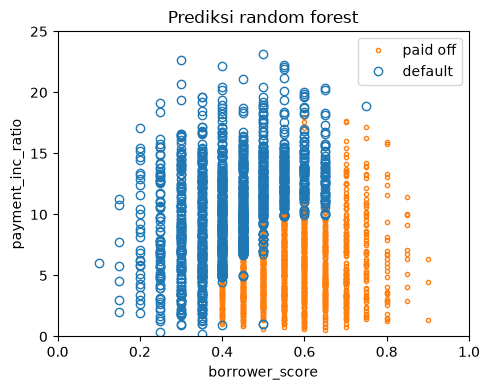

prediction
paid off    1517
default     1483
Name: count, dtype: int64


In [23]:
# Prediksi random forest (model terakhir dari loop: 495 pohon, max_depth=5)
predictions = X.copy()
predictions['prediction'] = rf.predict(X)

fig, ax = plt.subplots(figsize=(5, 4))

predictions.loc[predictions.prediction=='paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
predictions.loc[predictions.prediction=='default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')
ax.set_title('Prediksi random forest')

plt.tight_layout()
plt.show()
print(predictions['prediction'].value_counts())

**Interpretasi:** TODO-rf

### Variable Importance
**Teori:** Random forest tidak semudah satu pohon untuk diinterpretasi, tetapi dapat mengukur **pentingnya variabel**. Dua ukuran utama:
1. **Mean decrease in accuracy (permutation importance):** setelah model dilatih, nilai sebuah variabel pada data validasi/OOB **diacak (permutasi)**, sehingga hubungannya dengan outcome rusak. Penurunan akurasi model menunjukkan seberapa penting variabel tersebut. Di sini dihitung sebagai penurunan relatif $(\text{acc} - \text{acc}_{\text{shuffle}})/\text{acc}$, dirata-ratakan atas 3 split acak.
2. **Mean decrease in node impurity (Gini/entropy):** total penurunan impurity dari semua split yang memakai variabel tersebut, dirata-rata atas semua pohon (`feature_importances_` di scikit-learn). Cepat dihitung (tidak perlu data tambahan), tetapi **bias** terhadap variabel numerik / kategorikal dengan banyak level, dan hanya mengukur kontribusi di data training.

Berbeda dengan R (`randomForest`), scikit-learn tidak menyediakan *accuracy decrease* secara langsung, sehingga dihitung manual. Model dilatih pada seluruh `loan_data` (45.342 record) dengan semua prediktor (variabel kategorikal di-*one-hot encode* dengan `drop_first=True`). `n_jobs=-1` ditambahkan agar pelatihan memakai semua core CPU.

In [24]:
predictors = ['loan_amnt', 'term', 'annual_inc', 'dti',
              'payment_inc_ratio', 'revol_bal', 'revol_util',
              'purpose', 'delinq_2yrs_zero', 'pub_rec_zero',
              'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=int)
y = loan_data[outcome]
print('Ukuran X:', X.shape)

rf_all = RandomForestClassifier(n_estimators=500, random_state=1, n_jobs=-1)
rf_all.fit(X, y)

rf_all_entropy = RandomForestClassifier(n_estimators=500, random_state=1,
                                        criterion='entropy', n_jobs=-1)
print(rf_all_entropy.fit(X, y))

Ukuran X: (45342, 33)


RandomForestClassifier(criterion='entropy', n_estimators=500, n_jobs=-1,
                       random_state=1)


In [25]:
rf = RandomForestClassifier(n_estimators=500, random_state=1, n_jobs=-1)
scores = defaultdict(list)

# cross-validate skor pada beberapa split acak data
rng = np.random.default_rng(1)
for i in range(3):
    train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.3,
                                                          random_state=i)
    rf.fit(train_X, train_y)
    acc = metrics.accuracy_score(valid_y, rf.predict(valid_X))
    for column in X.columns:
        X_t = valid_X.copy()
        X_t[column] = rng.permutation(X_t[column].values)
        shuff_acc = metrics.accuracy_score(valid_y, rf.predict(X_t))
        scores[column].append((acc - shuff_acc) / acc)
print('Features sorted by their score:')
for score, feat in sorted([(round(np.mean(score), 4), feat) for
                           feat, score in scores.items()], reverse=True)[:12]:
    print(f'{feat:35s} {score:.4f}')

Features sorted by their score:
borrower_score                      0.0708
grade                               0.0322
term_60 months                      0.0304
annual_inc                          0.0103
payment_inc_ratio                   0.0093
dti                                 0.0066
purpose__small_business             0.0030
purpose_credit_card                 0.0028
loan_amnt                           0.0027
purpose_small_business              0.0016
purpose_other                       0.0015
emp_length                          0.0015


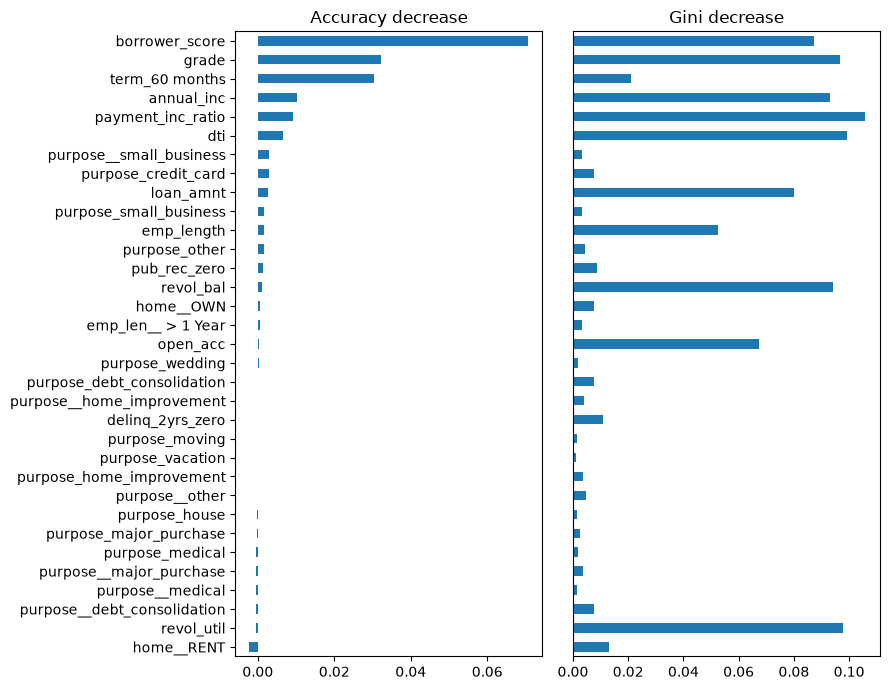

          feature  Accuracy decrease  Gini decrease  Entropy decrease
payment_inc_ratio             0.0093         0.1059            0.1067
              dti             0.0066         0.0994            0.1017
       revol_util            -0.0006         0.0976            0.1000
            grade             0.0322         0.0967            0.0911
        revol_bal             0.0010         0.0940            0.0978
       annual_inc             0.0103         0.0931            0.0945


In [26]:
df = pd.DataFrame({
    'feature': X.columns,
    'Accuracy decrease': [np.mean(scores[column]) for column in X.columns],
    'Gini decrease': rf_all.feature_importances_,
    'Entropy decrease': rf_all_entropy.feature_importances_,
})
df = df.sort_values('Accuracy decrease')

fig, axes = plt.subplots(ncols=2, figsize=(9, 7))
ax = df.plot(kind='barh', x='feature', y='Accuracy decrease',
             legend=False, ax=axes[0])
ax.set_ylabel('')
ax.set_title('Accuracy decrease')

ax = df.plot(kind='barh', x='feature', y='Gini decrease',
             legend=False, ax=axes[1])
ax.set_ylabel('')
ax.set_title('Gini decrease')
ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()
print(df.sort_values('Gini decrease', ascending=False).head(6).round(4).to_string(index=False))

**Interpretasi:** TODO-varimp

### Hyperparameters
**Teori:** Random forest relatif "robust", tetapi tetap memiliki hyperparameter yang memengaruhi performa:
- **`min_samples_leaf`** (R: `nodesize`): ukuran minimum daun. Default 1 untuk klasifikasi (5 untuk regresi di R). Nilai lebih besar membuat pohon lebih kecil dan lebih halus.
- **`max_leaf_nodes`** (R: `maxnodes`): jumlah maksimum daun per pohon. Default tidak dibatasi.
- **`max_features`** (R: `mtry`): banyaknya prediktor acak yang dipertimbangkan di setiap split.
- **`n_estimators`**: jumlah pohon. Semakin banyak umumnya semakin stabil (tidak menyebabkan overfit), hanya menambah waktu komputasi.

Tanpa pembatasan, pohon akan tumbuh sangat dalam dan forest bisa *overfit* pada data yang noisy. Hyperparameter dipilih dengan cross-validation atau **OOB error**. Kode tambahan berikut membandingkan OOB accuracy untuk kombinasi `min_samples_leaf` × `max_features` (200 pohon, data `loan_data` lengkap dengan prediktor di atas).

In [27]:
hp_rows = []
for leaf, mf in product([1, 5, 25, 100], ['sqrt', 0.5]):
    rf_hp = RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf, max_features=mf,
                                   oob_score=True, random_state=1, n_jobs=-1)
    rf_hp.fit(X, y)
    hp_rows.append({'min_samples_leaf': leaf, 'max_features': str(mf),
                    'train_acc': rf_hp.score(X, y), 'oob_acc': rf_hp.oob_score_})
hp_df = pd.DataFrame(hp_rows)
print(hp_df.round(4))
print()
print(hp_df.pivot_table(index='min_samples_leaf', columns='max_features', values='oob_acc').round(4))

   min_samples_leaf max_features  train_acc  oob_acc
0                 1         sqrt     1.0000   0.6597
1                 1          0.5     1.0000   0.6528
2                 5         sqrt     0.8719   0.6659
3                 5          0.5     0.9310   0.6583
4                25         sqrt     0.7194   0.6677
5                25          0.5     0.7393   0.6640
6               100         sqrt     0.6822   0.6670
7               100          0.5     0.6826   0.6633

max_features         0.5    sqrt
min_samples_leaf                
1                 0.6528  0.6597
5                 0.6583  0.6659
25                0.6640  0.6677
100               0.6633  0.6670


**Interpretasi:** TODO-rf_hp

## 6.4 Boosting
### The Boosting Algorithm
**Teori:** Boosting membangun ensemble secara **berurutan**: setiap model baru difokuskan pada record yang **salah diprediksi** oleh model-model sebelumnya. Versi klasik **AdaBoost** untuk outcome $y_i \in \{-1, 1\}$:
1. Inisialisasi $M$ (jumlah model) dan iterasi $m=1$. Bobot awal $w_i = 1/N$. Model ensemble $\hat F_0 = 0$.
2. Latih model $\hat f_m$ dengan bobot $w_i$ sehingga meminimalkan error tertimbang $e_m = \sum_i w_i I(\hat f_m(x_i) \ne y_i)$.
3. Tambahkan ke ensemble: $\hat F_m = \hat F_{m-1} + \alpha_m \hat f_m$, dengan $\alpha_m = \frac{\log(1-e_m)}{e_m}$.
4. Perbarui bobot: $w_i \leftarrow w_i \exp(\alpha_m I(\hat f_m(x_i) \ne y_i))$, sehingga record yang salah diprediksi diberi **bobot lebih besar**. Normalisasi bobot.
5. $m \leftarrow m+1$; ulangi hingga $m = M$.

**Gradient boosting** merumuskan ulang boosting sebagai optimisasi: setiap pohon baru dilatih pada **pseudo-residual** (gradien negatif dari fungsi loss). **Stochastic gradient boosting** menambahkan *subsampling* record (dan/atau kolom) di setiap iterasi, mirip random forest.

### XGBoost
**XGBoost** (*eXtreme Gradient Boosting*) adalah implementasi stochastic gradient boosting yang sangat populer dan efisien. Parameter utama:
- **`subsample`**: fraksi record yang disampel tiap iterasi (di sini 0,63, mirip bootstrap).
- **`learning_rate` (eta)**: faktor penyusutan (*shrinkage*) kontribusi tiap pohon (0–1). Nilai kecil mengurangi overfitting tetapi membutuhkan lebih banyak pohon.
- **`n_estimators`**: jumlah iterasi/pohon. **`max_depth`**: kedalaman maksimum pohon (default 6).
- **`objective`**: fungsi loss, `binary:logistic` untuk klasifikasi biner.

XGBoost membutuhkan outcome numerik 0/1, sehingga `default` dikodekan 1 dan `paid off` 0.

In [28]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = pd.Series([1 if o == 'default' else 0 for o in loan3000[outcome]])

xgb = XGBClassifier(objective='binary:logistic', subsample=.63,
                    eval_metric='error', random_state=1)
print(xgb.fit(X, y))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='error', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)


In [29]:
xgb_df = X.copy()
xgb_df['prediction'] = ['default' if p == 1 else 'paid off' for p in xgb.predict(X)]
# Catatan: kolom 1 = probabilitas kelas 1 (default). Notebook resmi memakai [:, 0],
# yang sebenarnya probabilitas 'paid off'.
xgb_df['prob_default'] = xgb.predict_proba(X)[:, 1]
print(xgb_df.head())

   borrower_score  payment_inc_ratio prediction  prob_default
0            0.40            5.11135   paid off      0.310127
1            0.40            5.43165    default      0.658862
2            0.70            9.23003    default      0.673718
3            0.40            2.33482   paid off      0.324800
4            0.45           12.10320    default      0.955004


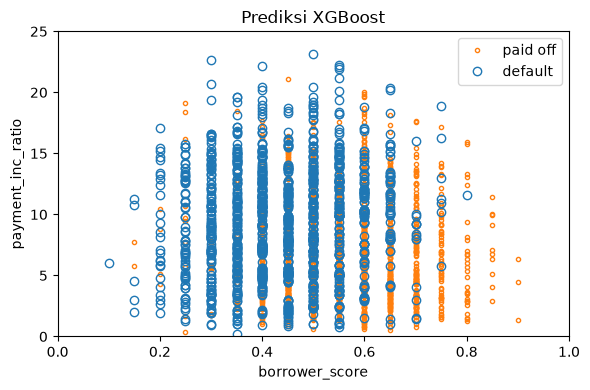

prediction
paid off    1625
default     1375
Name: count, dtype: int64


In [30]:
fig, ax = plt.subplots(figsize=(6, 4))

xgb_df.loc[xgb_df.prediction=='paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
xgb_df.loc[xgb_df.prediction=='default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')
ax.set_title('Prediksi XGBoost')

plt.tight_layout()
plt.show()
print(xgb_df['prediction'].value_counts())

**Interpretasi:** TODO-xgb

### Regularization: Avoiding Overfitting
**Teori:** Penerapan XGBoost secara "buta" mudah menghasilkan **overfitting**: model sangat akurat di data training tetapi buruk di data baru, dan prediksinya tidak stabil. XGBoost menyediakan beberapa cara mengendalikannya:
- **`learning_rate` (eta)** kecil dan **`subsample`** < 1 (stochastic boosting).
- **Regularisasi** pada fungsi biaya, mirip ridge/lasso pada regresi (Chapter 4). Untuk pohon dengan $T$ daun dan bobot daun $w_j$:
$$\text{Obj} = \sum_i L(y_i, \hat y_i) + \gamma T + \tfrac{1}{2}\lambda \sum_j w_j^2 + \alpha\sum_j |w_j|$$
  - **`reg_alpha`** ($\alpha$): penalti L1 (*Manhattan*, seperti lasso).
  - **`reg_lambda`** ($\lambda$): penalti L2 (*Euclidean squared*, seperti ridge).
  - **`gamma`**: penurunan loss minimum agar sebuah split dibuat.

  Nilai penalti yang besar menyusutkan bobot daun sehingga model lebih sederhana.

Dua model dibandingkan pada seluruh `loan_data` (10.000 record sebagai data validasi):
- **`xgb_default`**: tanpa regularisasi (`reg_lambda=0`, `learning_rate=0.3`, `subsample=1`).
- **`xgb_penalty`**: dengan regularisasi kuat (`reg_lambda=1000`, `learning_rate=0.1`, `subsample=0.63`).

In [31]:
predictors = ['loan_amnt', 'term', 'annual_inc', 'dti',
              'payment_inc_ratio', 'revol_bal', 'revol_util',
              'purpose', 'delinq_2yrs_zero', 'pub_rec_zero',
              'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=int)
y = pd.Series([1 if o == 'default' else 0 for o in loan_data[outcome]])

train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=10000, random_state=1)

xgb_default = XGBClassifier(objective='binary:logistic', n_estimators=250, max_depth=6,
                            reg_lambda=0, learning_rate=0.3, subsample=1,
                            eval_metric='error', random_state=1)
xgb_default.fit(train_X, train_y)

xgb_penalty = XGBClassifier(objective='binary:logistic', n_estimators=250, max_depth=6,
                            reg_lambda=1000, learning_rate=0.1, subsample=0.63,
                            eval_metric='error', random_state=1)
print(xgb_penalty.fit(train_X, train_y))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='error', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=250,
              n_jobs=None, num_parallel_tree=None, ...)


In [32]:
pred_default = xgb_default.predict_proba(train_X)[:, 1]
error_default = abs(train_y - pred_default) > 0.5
print('default (train): ', np.mean(error_default))

pred_default = xgb_default.predict_proba(valid_X)[:, 1]
error_default = abs(valid_y - pred_default) > 0.5
print('default (valid): ', np.mean(error_default))

pred_penalty = xgb_penalty.predict_proba(train_X)[:, 1]
print('penalty (train): ', np.mean(abs(train_y - pred_penalty) > 0.5))

pred_penalty = xgb_penalty.predict_proba(valid_X)[:, 1]
error_penalty = abs(valid_y - pred_penalty) > 0.5
print('penalty (valid): ', np.mean(error_penalty))

default (train):  0.10528549601041254
default (valid):  0.366
penalty (train):  0.31081998755022355
penalty (valid):  0.3306


Error training dan validasi dihitung untuk setiap jumlah iterasi (pohon) dengan `iteration_range`. **Catatan:** notebook resmi memakai `iteration_range=[1, n+1]`; di sini dipakai `(0, n)` yang secara tepat berarti "pakai $n$ pohon pertama" pada XGBoost versi terbaru.

In [33]:
results = []
for ntree_limit in range(1, 251):
    iteration_range = (0, ntree_limit)
    train_default = xgb_default.predict_proba(train_X, iteration_range=iteration_range)[:, 1]
    train_penalty = xgb_penalty.predict_proba(train_X, iteration_range=iteration_range)[:, 1]
    pred_default = xgb_default.predict_proba(valid_X, iteration_range=iteration_range)[:, 1]
    pred_penalty = xgb_penalty.predict_proba(valid_X, iteration_range=iteration_range)[:, 1]
    results.append({
        'iterations': ntree_limit,
        'default train': np.mean(abs(train_y - train_default) > 0.5),
        'penalty train': np.mean(abs(train_y - train_penalty) > 0.5),
        'default test': np.mean(abs(valid_y - pred_default) > 0.5),
        'penalty test': np.mean(abs(valid_y - pred_penalty) > 0.5),
    })

results = pd.DataFrame(results)
print(results.head())
print(results.iloc[[9, 49, 99, 249]])

   iterations  default train  penalty train  default test  penalty test
0           1       0.342058       0.354083        0.3488        0.3567
1           2       0.331985       0.343727        0.3412        0.3455
2           3       0.325335       0.341520        0.3416        0.3458
3           4       0.322619       0.337898        0.3381        0.3444
4           5       0.319846       0.339907        0.3388        0.3426
     iterations  default train  penalty train  default test  penalty test
9            10       0.310311       0.334984        0.3372        0.3371
49           50       0.255758       0.326976        0.3374        0.3308
99          100       0.203724       0.322817        0.3484        0.3283
249         250       0.105285       0.310820        0.3660        0.3306


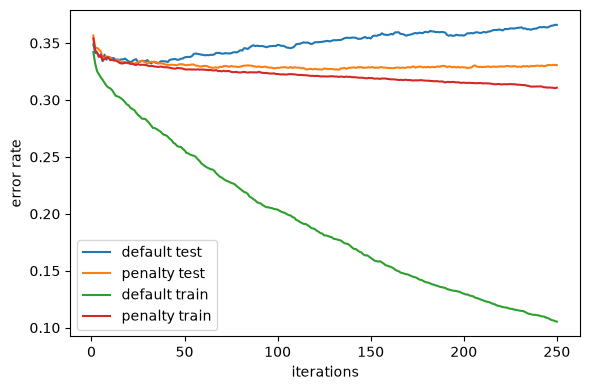

In [34]:
ax = results.plot(x='iterations', y='default test', figsize=(6, 4))
results.plot(x='iterations', y='penalty test', ax=ax)
results.plot(x='iterations', y='default train', ax=ax)
results.plot(x='iterations', y='penalty train', ax=ax)
ax.set_ylabel('error rate')
plt.tight_layout()
plt.show()

**Interpretasi:** TODO-regularization

### Hyperparameters and Cross-Validation
**Teori:** XGBoost memiliki banyak hyperparameter yang saling berinteraksi; yang terpenting:
- **`learning_rate` (eta):** shrinkage, 0–1 (default 0,3).
- **`n_estimators`:** jumlah pohon; berinteraksi dengan eta (eta kecil butuh lebih banyak pohon).
- **`max_depth`:** kedalaman pohon (default 6). Berbeda dengan random forest yang memakai pohon dalam, boosting biasanya memakai pohon **dangkal** agar tidak menangkap interaksi palsu.
- **`subsample`** dan **`colsample_bytree`:** fraksi record dan prediktor yang disampel.
- **`reg_lambda`**, **`reg_alpha`**: regularisasi.

Pemilihan dilakukan dengan **K-fold cross-validation**: data dibagi menjadi $K$ fold; untuk setiap kombinasi hyperparameter, model dilatih $K$ kali (setiap kali satu fold menjadi data validasi) lalu error dirata-rata. Kombinasi dengan error CV terendah dipilih.

Buku menguji grid `eta` ∈ {0.1, 0.5, 0.9} × `max_depth` ∈ {3, 6, 9} (9 kombinasi × 5 fold = 45 model, masing-masing 250 pohon) pada seluruh `loan_data`. Grid ini tetap dijalankan lengkap; `n_jobs=-1` dan `tree_method='hist'` dipakai agar cepat.

In [35]:
rng = np.random.default_rng(1)
idx = rng.choice(range(5), size=len(X), replace=True)   # penugasan fold acak
error = []
for eta, max_depth in product([0.1, 0.5, 0.9], [3, 6, 9]):
    xgb = XGBClassifier(objective='binary:logistic', n_estimators=250,
                        max_depth=max_depth, learning_rate=eta,
                        eval_metric='error', tree_method='hist', n_jobs=-1,
                        random_state=1)
    cv_error = []
    for k in range(5):
        fold_idx = idx == k
        train_X = X.loc[~fold_idx]; train_y = y[~fold_idx]
        valid_X = X.loc[fold_idx]; valid_y = y[fold_idx]

        xgb.fit(train_X, train_y)
        pred = xgb.predict_proba(valid_X)[:, 1]
        cv_error.append(np.mean(abs(valid_y - pred) > 0.5))
    error.append({
        'eta': eta,
        'max_depth': max_depth,
        'avg_error': np.mean(cv_error)
    })
    print(error[-1])
errors = pd.DataFrame(error)

{'eta': 0.1, 'max_depth': 3, 'avg_error': np.float64(0.3279046724591187)}


{'eta': 0.1, 'max_depth': 6, 'avg_error': np.float64(0.3350876243803089)}


{'eta': 0.1, 'max_depth': 9, 'avg_error': np.float64(0.3465549484394411)}


{'eta': 0.5, 'max_depth': 3, 'avg_error': np.float64(0.33817904729635473)}


{'eta': 0.5, 'max_depth': 6, 'avg_error': np.float64(0.3712588180890971)}


{'eta': 0.5, 'max_depth': 9, 'avg_error': np.float64(0.3732290010336298)}


{'eta': 0.9, 'max_depth': 3, 'avg_error': np.float64(0.35322786992594346)}


{'eta': 0.9, 'max_depth': 6, 'avg_error': np.float64(0.3876248004357545)}


{'eta': 0.9, 'max_depth': 9, 'avg_error': np.float64(0.38107394704358655)}


In [36]:
# Error CV (%) untuk setiap kombinasi eta x max_depth
print(errors.pivot_table(index='eta', columns='max_depth', values='avg_error') * 100)

max_depth          3          6          9
eta                                       
0.1        32.790467  33.508762  34.655495
0.5        33.817905  37.125882  37.322900
0.9        35.322787  38.762480  38.107395


**Interpretasi:** TODO-cv

## Ringkasan Chapter 6
TODO-summary